## Decision Tree

- is a supervised learning model.
- Decision support tool that uses a tree-like graph or model of decisions and their possible consequences.
- Various variations such as Boosted decision tree, decision forest, etc.
- Decision tree and its variations can be used for categorical as well as continuous variables.

#### Example:

![](images\dt1.PNG)

We ask questions depending on every parameters eg: whether based on the income levels loan will be approved or not.

![](images\dt2.PNG)

Observe all applications with high income levels were approved. Goal of decision tree in classification is to come up with __pure subset__. __Pure subset is one where you have only one outcome__.

And in the case above we have a subset with only one outcome i.e., loan status as Yes. So we do not split this further.

Similarly for low income we have only one outcome and we have reached the pure subset and we don't split it further.

![](images\dt3.PNG)

But for medium income we have 2 loan status levels and is not a pure subset so we have to split it further. So we can split further based on credit score.

![](images\dt4.PNG)

So we have to split further based on __Employment type__.

![](images\dt5.PNG)

So whenever we get a new application we can traverse through these nodes to find the corresponding loan status.

As this whole set up looks like an inverted tree hence the name - __decision tree__.

#### Terminologies used in Decision tree

1. __Root node__ - It is the first node here that represents the entire dataset. 

2. __Splitting__ - It is the process of forming various decision nodes is known as splitting.

3. When a subnode splits into further subnodes then its known as __Decision node__.

4. And when we do not want to split a decision node further (pure subset) then its known as a __leaf__ or __terminal node__.

5. Subsection of this tree which has a decison node or leaf then its known as __branch__ or __subtree__.

![](images\dt6.PNG)

***

### ML A-Z

![](images\ml1.PNG)

![](images\ml2.PNG)

Split is done by decision tree algorithm such that we can maximize the number of categories in each of these splits.

Eg:
- Split 1 maximizes the number of red split in bottom i.e., x2 < 60
- Split 2 maximizes the number of red andd green splits at x1 < 50 and we get uniform classes.
- Split 3 seperate values as x1 < 70 or more.
- Split 4 then splits values at x2 < 20.

In reality, in background split is trying to minimize entropy.

![](images\dsp.PNG)

##### We can also go with a multi-dimensional dataset and can ask a mix of questions to aid in splitting.

# Decision tree

A Decision Tree is a popular non-parametric, supervised machine learning algorithm used for both classification (predicting a categorical label) and regression (predicting a continuous numeric value) tasks. It operates like a flowchart, breaking down a complex dataset into smaller, more manageable subsets based on simple if-then decision rules.

In plain English, **non-parametric** doesn't mean a model has *no* parameters. Instead, it means the model **doesn't make rigid assumptions about the shape or structure of your data beforehand**, and the number of parameters it uses can grow as you give it more data.


### The Foggy Mountain Analogy

Imagine you are trying to map out a landscape:

* **A Parametric Approach (like Linear Regression):** You assume ahead of time that the terrain is a perfectly flat, sloped ramp. All you need to do is calculate two fixed numbers: the tilt (slope) and the starting height (intercept). No matter how bumpy or wild the real mountain is, your model is forced to draw a straight line.
* **A Non-Parametric Approach (like a Decision Tree):** You make no assumptions about what the mountain looks like. If there are cliffs, valleys, or winding paths, the model adapts by carving out specific rules (e.g., *"If altitude > 500m AND steepness > 30°, turn left"*). As you gather more data points, the tree grows more branches to capture all the local details.


### Parametric vs. Non-Parametric

| Characteristic | Parametric Models | Non-Parametric Models |
| --- | --- | --- |
| **Core Idea** | Assumes a fixed mathematical form (e.g., a straight line or bell curve) before looking at the data. | Learns the shape directly from the data without pre-fixed structure. |
| **Parameters** | Fixed count (doesn't grow with more training data). | Flexible count (can grow as data complexity or size increases). |
| **Best Used For** | Clear linear trends, smaller datasets, or when fast computation/interpretability is needed. | Complex, non-linear relationships, multi-modal distributions, and large datasets. |
| **Key Limitation** | High bias: If the assumption is wrong (e.g., fitting a straight line to a curve), performance is poor. | Prone to overfitting: Can memorize noise if not controlled (e.g., growing trees too deep). |
| **Examples** | Linear Regression, Logistic Regression | Decision Trees, K-Nearest Neighbors (KNN), SVMs with RBF kernel |


### How a Decision Tree Uses Non-Parametric Learning

1. **Starts with zero assumptions:** It doesn't care if your data follows a normal distribution, has non-linear patterns, or contains complex interactions between features.
2. **Splits space step-by-step:** It continuously divides your dataset into smaller sub-regions using `IF-THEN` rules based on feature thresholds.
3. **Grows with data:** If you give it 100 data points, a short tree with 3 splits might suffice. If you give it 100,000 complex data points, it can grow into a deep tree with hundreds of decisions to fit the data boundaries accurately.



Here is the complete hands-on guide covering all three concepts: a non-linear dataset demo, a visual comparison between parametric and non-parametric fitting, and a practical walkthrough on controlling tree depth to prevent overfitting.


## 1 & 2. Python Demo: Non-Linear Fitting & Model Comparison

This complete, runnable Python script generates a non-linear curve (a noisy sine wave) and compares **Linear Regression** (Parametric) against a **Decision Tree** (Non-Parametric).


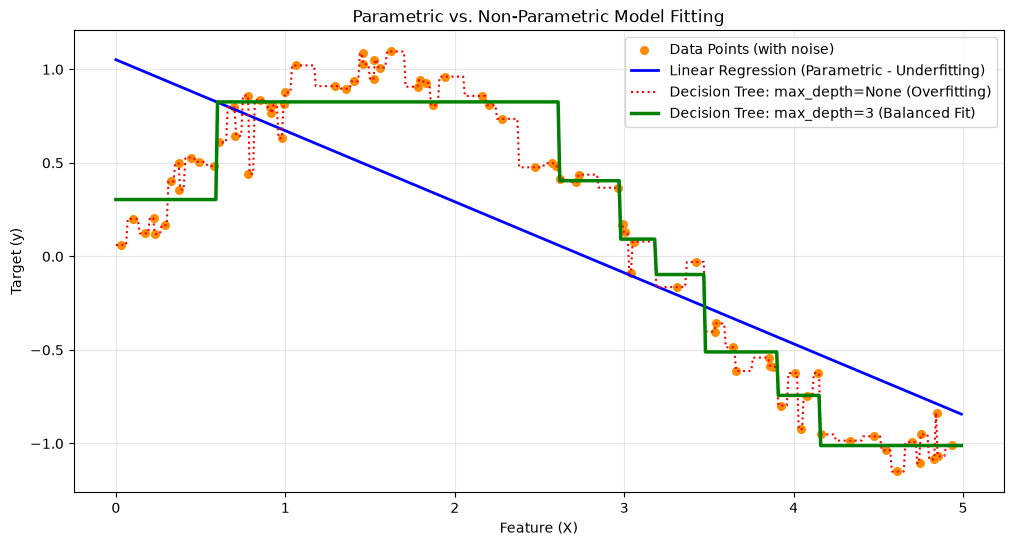

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# Step 1: Create a synthetic non-linear dataset (Noisy Sine Wave)
np.random.seed(42)
X = np.sort(5 * np.random.rand(80, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, X.shape[0])  # Non-linear curve + noise

# Step 2: Fit Parametric vs Non-Parametric Models
# Parametric: Assumes a rigid straight line (y = mx + c)
lin_reg = LinearRegression()
lin_reg.fit(X, y)

# Non-Parametric (Unconstrained): Grows as deep as needed to memorize every point
dt_unconstrained = DecisionTreeRegressor(max_depth=None, random_state=42)
dt_unconstrained.fit(X, y)

# Non-Parametric (Controlled): Constrained to learn general step-wise rules
dt_optimal = DecisionTreeRegressor(max_depth=3, random_state=42)
dt_optimal.fit(X, y)

# Step 3: Generate predictions across the continuous input range
X_test = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]
y_pred_lin = lin_reg.predict(X_test)
y_pred_unconstrained = dt_unconstrained.predict(X_test)
y_pred_optimal = dt_optimal.predict(X_test)

# Step 4: Visualize the results
plt.figure(figsize=(12, 6))
plt.scatter(X, y, color='darkorange', label='Data Points (with noise)', s=30)
plt.plot(X_test, y_pred_lin, color='blue', linewidth=2, label='Linear Regression (Parametric - Underfitting)')
plt.plot(X_test, y_pred_unconstrained, color='red', linewidth=1.5, linestyle=':', label='Decision Tree: max_depth=None (Overfitting)')
plt.plot(X_test, y_pred_optimal, color='green', linewidth=2.5, label='Decision Tree: max_depth=3 (Balanced Fit)')

plt.xlabel('Feature (X)')
plt.ylabel('Target (y)')
plt.title('Parametric vs. Non-Parametric Model Fitting')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


### What the Plot Reveals

* **Linear Regression (Blue Line):** Fails to capture the curve because it is constrained to a fixed formula $y = w \cdot x + b$. It suffers from **high bias** (underfitting).
* **Decision Tree - Unconstrained (Red Dotted Line):** Jaggedly connects almost every noisy training point. It fits the training data perfectly but fails to capture the true underlying wave. It suffers from **high variance** (overfitting).
* **Decision Tree - Balanced (Green Step-Line):** Approximates the smooth sine wave by carving the space into step-wise intervals (`IF X < 1.5 THEN y ≈ 0.97`), adapting flexibly to the non-linear shape without chasing noisy outliers.


### Model Comparison Summary

| Concept / Algorithm | Core Idea | Best Used For | Key Limitation / Trade-off |
| --- | --- | --- | --- |
| **Linear Regression** *(Parametric)* | Fits a pre-defined linear equation with fixed weights ($w_1, w_2, \dots$). | Datasets with clear linear relationships; small sample sizes. | Cannot adapt to non-linear patterns or complex feature interactions. |
| **Unconstrained Decision Tree** *(Non-Parametric)* | Splits data recursively until every leaf node contains pure subsets. | Rapid baseline modeling on complex non-linear data. | Prone to memorizing random noise (extreme overfitting) if left unchecked. |
| **Pruned / Depth-Limited Tree** *(Non-Parametric)* | Restricts maximum branch splits using threshold hyperparameters. | Capturing non-linear decision boundaries with strong generalization. | Step-wise boundary approximation; sensitive to small variations in data. |


## 3. Controlling Tree Depth to Prevent Overfitting

Because non-parametric models can grow arbitrarily complex as training data expands, **regularization** (controlling model complexity) is required to ensure good performance on unseen data.

In Decision Trees, this process is called **pruning**.

### Key Hyperparameters for Pruning

1. **`max_depth`:** Limits how deep the tree can grow.
* *Low value (e.g., 2–4):* Simple model, prevents overfitting.
* *High value (e.g., >15) or `None`:* Deep tree, risks memorizing noise.


2. **`min_samples_split`:** Minimum number of data points required in a node before it is allowed to split further.
* Increasing this value prevents the tree from creating splits for tiny clusters of outliers.


3. **`min_samples_leaf`:** Minimum number of samples required to be at a leaf (terminal node).
* A higher number guarantees that every final rule applies to a statistically meaningful group of observations.



### Code Walkthrough: Depth Control & Cross-Validation

This code compares different tree depths on training vs. validation accuracy to pinpoint the optimal stopping point:


In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import pandas as pd

# Generate a synthetic classification dataset with complex boundaries
X, y = make_classification(
    n_samples=1000, 
    n_features=10, 
    n_informative=5, 
    n_redundant=2, 
    random_state=42
)

# Split into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Experiment with different max_depth settings
depths = [1, 3, 5, 10, 20, None]
results = []

for depth in depths:
    # Initialize tree with depth constraint and minimum leaf sample requirement
    clf = DecisionTreeClassifier(
        max_depth=depth, 
        min_samples_leaf=5, 
        random_state=42
    )
    clf.fit(X_train, y_train)
    
    # Calculate accuracy scores
    train_acc = clf.score(X_train, y_train)
    test_acc = clf.score(X_test, y_test)
    
    results.append({
        'Max Depth': str(depth),
        'Train Accuracy': f"{train_acc:.1%}",
        'Test Accuracy': f"{test_acc:.1%}",
        'Status': 'Underfitting' if train_acc < 0.8 else ('Overfitting' if train_acc - test_acc > 0.1 else 'Well Balanced')
    })

# Render summary table
df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))


Max Depth Train Accuracy Test Accuracy        Status
        1          70.9%         77.0%  Underfitting
        3          89.2%         91.0% Well Balanced
        5          93.5%         91.0% Well Balanced
       10          96.6%         92.0% Well Balanced
       20          96.6%         92.0% Well Balanced
     None          96.6%         92.0% Well Balanced



### Core Takeaways

* **Underfitting Region (`max_depth` = 1 or 2):** The model is too restricted to capture the actual underlying relationships. Both training and testing accuracy remain low.
* **Optimal Region (`max_depth` = 3 to 5):** The model captures main structural rules while ignoring individual noise points. Training accuracy and testing accuracy remain close.
* **Overfitting Region (`max_depth` > 10 or `None`):** Training accuracy reaches ~100%, but testing accuracy declines. The gap between training and testing performance signals that the non-parametric model grew too complex.

## Visualizing a Decision Tree
Visualizing a Decision Tree is like opening up a flowchart or a diagnostic manual. Unlike "black box" models (such as deep neural networks) whose inner workings are hard to decipher, a Decision Tree provides clear, step-by-step **`IF-THEN` rules** that show exactly why a prediction was made.

Scikit-Learn provides two built-in ways to inspect these rules: **Text-Based Trees (`export_text`)** for fast terminal logs and **Graphical Flowcharts (`plot_tree`)** for visual reports.


### Visualization Methods Compared

| Tool / Method | Core Idea | Best Used For | Key Limitation / Trade-off |
| --- | --- | --- | --- |
| **`export_text`** | Generates an indented ASCII text hierarchy of conditional rules (` | --- feature <= threshold`). | Quick debugging in terminal logs, copy-pasting into documentation, or inspecting deep trees. |
| **`plot_tree`** | Renders a publication-ready Matplotlib diagram with boxes, arrows, and node statistics. | Presentations, beginner explanations, and smaller trees where visual layout helps understanding. | Can become cluttered and unreadable if the tree is too wide or deep (`max_depth` > 5). |
| **`graphviz` / `dtreeviz**` | External libraries that render highly styled, interactive, or distribution-filled diagrams. | Production reports and executive slide decks requiring publication-grade visuals. | Requires installing external software dependencies outside standard Python packages. |

### How to Read a Decision Tree Node

When you plot a tree graphically, each box (node) contains critical statistical details about that specific decision step:

1. **Split Condition (Top Line):** The rule tested at this step (e.g., `petal length (cm) <= 2.45`). If `True`, go left; if `False`, go right.
2. **`gini` / `entropy` (Impurity):** Measures how mixed the data is at this node. A Gini score of `0.0` means the node is **pure** (all samples belong to a single class).
3. **`samples`:** The total number of training data points that reached this specific node.
4. **`value`:** The distribution of classes among those samples (e.g., `[50, 50, 0]` means 50 samples of Class 0, 50 of Class 1, and 0 of Class 2).
5. **`class`:** The majority class label assigned to any sample ending up in this node.


### Hands-On Python Code Demo

This complete script trains a Decision Tree on the classic **Iris Flower Dataset** and demonstrates both visualization techniques side-by-side.


METHOD 1: TEXT-BASED DECISION TREE RULES
|--- petal length (cm) <= 2.45
|   |--- weights: [50.00, 0.00, 0.00] class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- weights: [0.00, 47.00, 1.00] class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- weights: [0.00, 2.00, 4.00] class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- weights: [0.00, 1.00, 2.00] class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- weights: [0.00, 0.00, 43.00] class: 2


Generating Graphical Tree Plot...


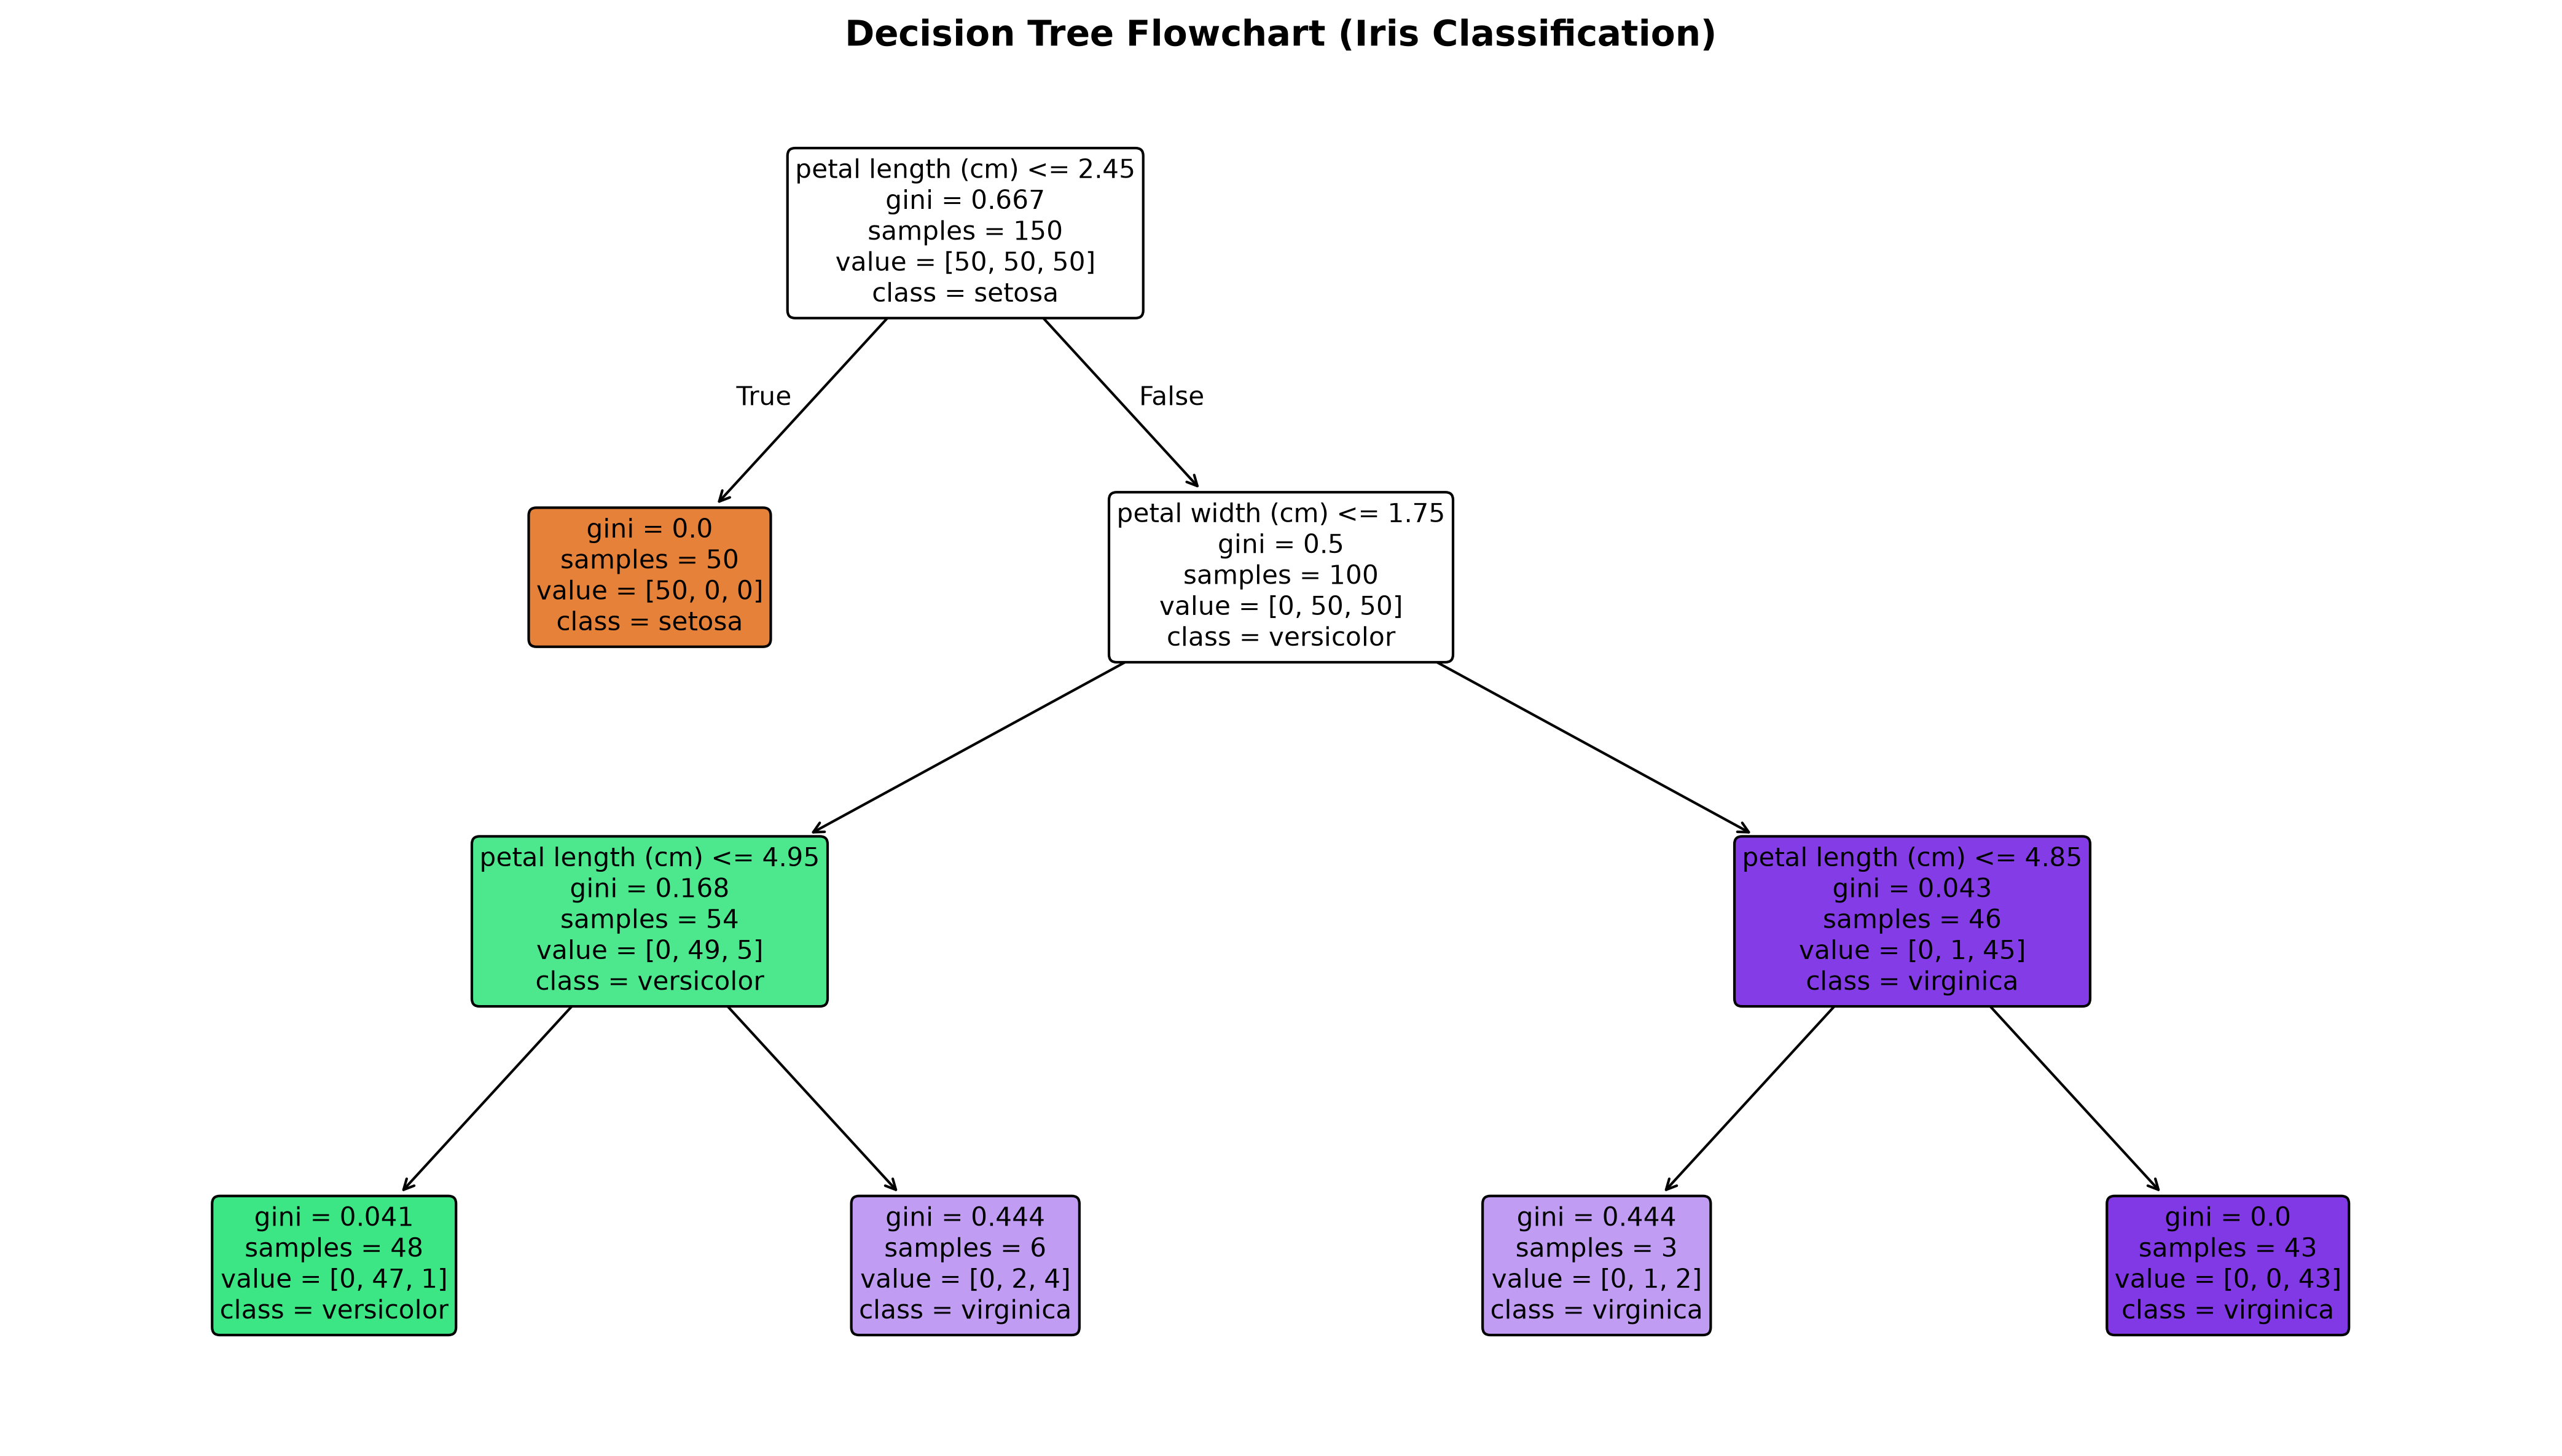

In [3]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Step 1: Load dataset and train a readable Decision Tree
iris = load_iris()
X, y = iris.data, iris.target
feature_names = iris.feature_names
class_names = iris.target_names.tolist()

# We cap max_depth to 3 so the visual layout remains clean and easy to read
clf = DecisionTreeClassifier(max_depth=3, random_state=42)
clf.fit(X, y)

# ---------------------------------------------------------
# Method 1: Text-Based Tree Rules (export_text)
# ---------------------------------------------------------
print("=" * 50)
print("METHOD 1: TEXT-BASED DECISION TREE RULES")
print("=" * 50)

tree_rules = export_text(
    clf, 
    feature_names=feature_names,
    show_weights=True  # Shows class counts at each leaf
)
print(tree_rules)

# ---------------------------------------------------------
# Method 2: Graphical Flowchart Plotting (plot_tree)
# ---------------------------------------------------------
print("\nGenerating Graphical Tree Plot...")

plt.figure(figsize=(14, 8), dpi=300)
plot_tree(
    clf,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,          # Colors nodes based on majority class & impurity
    rounded=True,         # Adds rounded corners to boxes
    impurity=True,        # Displays Gini impurity score
    fontsize=10
)

plt.title("Decision Tree Flowchart (Iris Classification)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()




### What to Look Out For in the Visual Output

* **Node Color Intensity:** In `plot_tree`, brighter colors indicate high confidence (low Gini impurity), whereas pale or white boxes mean the dataset is still mixed between multiple classes.
* **Leaf Nodes (Terminal Ends):** Boxes without outgoing arrows at the bottom are the final decision buckets. Every new flower passed into this model will follow down the arrows until it lands in one of these leaves.